# IT9002 Lab 1.2: Fundamentals of Text Preprocessing

**Unit 01: Language, Text, and the NLP Pipeline**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, the following should be clear:

- Describing a text corpus with counts: documents, tokens, types, class balance and message length
- Finding, counting and replacing patterns in raw text with regular expressions
- What tokenization, normalization, stop-word removal, stemming and lemmatization each keep and remove, measured in tokens and types
- How the Porter, Snowball, WordNet and spaCy tools differ on the same words, on a whole corpus, and in running time
- Reading part-of-speech tags produced by spaCy

## Data

- **SMS Spam Collection** (Almeida, Hidalgo and Yamakami, 2011), UCI Machine Learning Repository dataset 228, https://archive.ics.uci.edu/dataset/228/sms+spam+collection, license CC BY 4.0.

- The file `sms_spam.csv` (473 KB, on Moodle).

The file `sms_spam.csv` can be downloaded from Moodle. Download it to your computer, then run the cell below. If the file is already available in the runtime, the cell loads it directly; otherwise, it opens a file-upload dialog.

`pd.read_csv()` reads the file into a **DataFrame**, and `head()` displays its first 5 rows.

In [1]:
from pathlib import Path
import pandas as pd

DATA = "sms_spam.csv"
path = next((p for p in (Path(DATA), Path("data") / DATA) if p.exists()), None)
if path is None:
    from google.colab import files
    files.upload()
    path = Path(DATA)

df = pd.read_csv(path)
print(df.shape)
df.head()

(5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


The file holds 5,572 messages, each containing a label: `ham` for a normal message and `spam` for an unwanted message. 

The first rows illustrate several characteristics of the raw text, including abbreviations, repeated punctuation, and inconsistent use of letter case.

## Setup

Both NLTK and spaCy are preinstalled in Google Colab, so the cell below does not install them there. In other environments, the libraries will be installed if they are not already available.

In [2]:
import importlib.util, subprocess, sys

for pkg in ("nltk", "spacy"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

The cell below:

- Downloads the **4** NLTK resources (~17 MB) used in this lab.

- Imports the NLTK tools used later.

- Loads the `en_core_web_sm` pipeline from spaCy, and downloads it first if it is not available.

In [3]:
import re, time, html, unicodedata
from collections import Counter

import nltk
import spacy

for resource in ("punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"):
    nltk.download(resource, quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer

try:
    nlp_spacy = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp_spacy = spacy.load("en_core_web_sm")

The cell below prints the versions of Python, pandas, NLTK, spaCy, and the loaded spaCy pipeline.

In [4]:
import platform
print("Python", platform.python_version())
print("pandas", pd.__version__, "| NLTK", nltk.__version__, "| spaCy", spacy.__version__,
      "| model", nlp_spacy.meta["name"], nlp_spacy.meta["version"])

Python 3.11.9
pandas 3.0.2 | NLTK 3.9.4 | spaCy 3.8.16 | model core_web_sm 3.8.0


## 1. The Corpus as Data

A **corpus** is a collection of documents. In this dataset, each document is an individual message paired with a label.

A useful first step in describing a corpus is to summarize its basic properties, such as:

- The number of documents.
- The distribution of labels.
- The length of the documents.

The cell below counts how many messages belong to each label.

In [5]:
counts = df["label"].value_counts()
print(counts)
print(f"spam share: {counts['spam'] / len(df):.1%}")

label
ham     4825
spam     747
Name: count, dtype: int64
spam share: 13.4%


747 of the 5,572 messages are **spam**, representing 13.4% of the corpus. The two classes are therefore **imbalanced**. 

A model that predicts `ham` for every message would still achieve an accuracy of 86.6%. For this reason, the performance of a spam classifier should also be evaluated specifically on how well it identifies spam messages.

The cell below counts the words and the characters in each message and summarizes them.

In [6]:
words = df["message"].str.split().str.len()
print(f"words per message: mean {words.mean():.1f}, median {words.median():.0f}, "
      f"shortest {words.min()}, longest {words.max()}")
print(f"characters per message: mean {df['message'].str.len().mean():.1f}")

words per message: mean 15.5, median 12, shortest 1, longest 171
characters per message: mean 80.1


The messages in the corpus are generally short. The median message length is 12 words, while the mean is higher at 15.5 words because a small number of longer messages increases the average. 

These word counts are based on splitting the text at spaces. A tokenizer may divide the same text differently and can produce a different token count.

Message `101` is used as an example throughout the lab so that the effect of each operation can be observed on the same text.

The cell below prints this message.

In [7]:
print(df.loc[101, "message"])

I'm still looking for a car to buy. And have not gone 4the driving test yet.


The message contains several features that require different preprocessing decisions: a contraction, a sentence boundary, a negation, and the string `4the`.

## 2. Regular Expressions

A **regular expression** is a pattern used to search, count, split, or replace parts of text. The normalization steps in this lab use regular expressions to identify specific text patterns.

The pattern `\d{5,}` matches a sequence of five or more digits. The function `re.findall()` returns all occurrences that match the pattern in a given string.

The cell below applies this pattern to a spam message.

In [8]:
m = df.loc[2, "message"]
print(m)
print(re.findall(r"\d{5,}", m))                  # every run of 5 or more digits

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
['87121', '08452810075']


The message contains two sequences of five or more digits: a short code and a phone number.

The cell below applies five **regular-expression patterns** to every message and reports the proportion of spam and ham messages that contain each pattern.

The `r` prefix creates a raw string, which keeps backslashes unchanged. The pattern `\b` marks a word boundary, so `\b[A-Z]{3,}\b` matches a complete word containing three or more capital letters.

In [9]:
patterns = {
    "5+ consecutive digits": r"\b\d{5,}\b",
    "Word in all capitals":        r"\b[A-Z]{3,}\b",
    "Exclamation mark":       r"!",
    "Currency amount":         r"[£$]\d",
    "Web address":             r"(?:https?://|www\.)",
}
spam = df[df["label"] == "spam"]["message"]
ham = df[df["label"] == "ham"]["message"]
shares = pd.DataFrame({
    "spam": {name: spam.str.contains(p).mean() for name, p in patterns.items()},
    "ham":  {name: ham.str.contains(p).mean() for name, p in patterns.items()},
})
shares.style.format("{:.1%}")

,spam,ham
5+ consecutive digits,75.5%,0.1%
Word in all capitals,70.4%,7.1%
Exclamation mark,48.9%,11.6%
Currency amount,34.1%,0.2%
Web address,13.9%,0.0%


Approximately 3/4 of spam messages contain a sequence of five or more digits, and about 7/10 contain a word written entirely in capital letters. In contrast, these patterns appear in very few ham messages.

These differences show that simple surface features can already provide useful evidence for distinguishing spam from ham before any model is trained. This also illustrates why normalization should be applied carefully, since removing or altering these features may discard useful information.

The cell below presents the same results as a bar chart, which illustrates the gap between the two classes for each pattern.

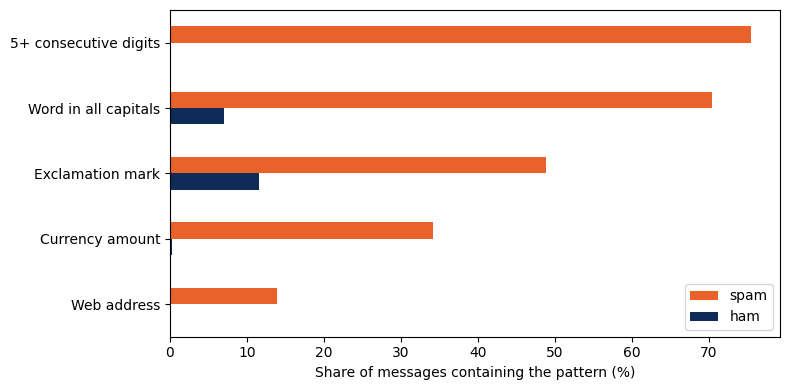

In [10]:
import matplotlib.pyplot as plt

ax = (shares * 100).plot.barh(figsize=(8, 4), color=["#E8622A", "#0F2B58"])
ax.set_xlabel("Share of messages containing the pattern (%)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 3. Tokenization

**Tokenization** is the process of dividing text into smaller units called **tokens**. A **tokenizer** applies a set of rules to determine where one token ends and the next begins.

Different tokenization methods may split the same text differently, which can produce different tokens and different token counts.

The cell below applies three tokenization methods to the same sentence:

- Python's whitespace-based `split()`.
- NLTK's rule-based `word_tokenize()`.
- A regular expression that keeps only sequences of word characters.

In [11]:
s = "Don't stop at the U.S. border."
for name, tokens in (("whitespace", s.split()),
                     ("NLTK word_tokenize", word_tokenize(s)),
                     ("regex \\w+", re.findall(r"\w+", s))):
    print(f"{name:20s} {len(tokens):2d} tokens  {tokens}")

whitespace            6 tokens  ["Don't", 'stop', 'at', 'the', 'U.S.', 'border.']
NLTK word_tokenize    8 tokens  ['Do', "n't", 'stop', 'at', 'the', 'U.S.', 'border', '.']
regex \w+             8 tokens  ['Don', 't', 'stop', 'at', 'the', 'U', 'S', 'border']


The three tokenizers produce different representations of the same sentence:

- The whitespace-based `split()` keeps the period attached to `border`.
- NLTK's `word_tokenize()` separates `Do` from `n't` while keeping `U.S.` as a single token.
- The regular-expression tokenizer splits `Don't` at the apostrophe, separates `U.S.` into individual letters, and removes punctuation.

These differences show that no single tokenization method is suitable for every task. The choice of tokenizer depends on which parts of the original text need to be preserved.

The cell below applies the same three tokenization methods to message `101`.

In [12]:
m = df.loc[101, "message"]
for name, tokens in (("whitespace", m.split()),
                     ("NLTK word_tokenize", word_tokenize(m)),
                     ("regex \\w+", re.findall(r"\w+", m))):
    print(f"{name:20s} {len(tokens):2d} tokens  {tokens}")

whitespace           16 tokens  ["I'm", 'still', 'looking', 'for', 'a', 'car', 'to', 'buy.', 'And', 'have', 'not', 'gone', '4the', 'driving', 'test', 'yet.']
NLTK word_tokenize   19 tokens  ['I', "'m", 'still', 'looking', 'for', 'a', 'car', 'to', 'buy', '.', 'And', 'have', 'not', 'gone', '4the', 'driving', 'test', 'yet', '.']
regex \w+            17 tokens  ['I', 'm', 'still', 'looking', 'for', 'a', 'car', 'to', 'buy', 'And', 'have', 'not', 'gone', '4the', 'driving', 'test', 'yet']


The same message produces 16, 19, and 17 tokens depending on the tokenizer used.

The cell below applies each tokenizer to the entire corpus and prints:

- The total number of **tokens**.
- The number of **types**, representing the distinct tokens that appear in the corpus.

In [13]:
tokenizers = {
    "whitespace": str.split,
    "NLTK word_tokenize": word_tokenize,
    "regex \\w+": lambda t: re.findall(r"\w+", t),
}
rows = []
for name, fn in tokenizers.items():
    tokens = [tok for msg in df["message"] for tok in fn(msg)]
    rows.append({"tokenizer": name, "tokens": len(tokens), "types": len(set(tokens))})
pd.DataFrame(rows).set_index("tokenizer")

,tokens,types
tokenizer,,
whitespace,86335,15585
NLTK word_tokenize,104193,11520
regex \w+,90106,10864


The NLTK tokenizer produces the largest number of tokens, with 104,193 in total, because it separates punctuation from surrounding words. In contrast, the whitespace-based tokenizer produces the largest number of types, with 15,585 distinct forms, because strings such as `word`, `word.`, and `word...` are treated as different tokens.

The regular-expression tokenizer keeps only sequences of word characters, which removes punctuation and changes how forms containing apostrophes or other symbols are represented.

**Sentence splitting** is the process of dividing a document into individual sentences. A period does not always indicate the end of a sentence, since it can also appear in abbreviations or decimal numbers.

NLTK's `sent_tokenize()` uses a trained model called **Punkt** to identify likely sentence boundaries while distinguishing them from other uses of punctuation.

The cell below applies sentence splitting to a spam message and to a sentence containing abbreviations.

In [14]:
print(sent_tokenize(df.loc[2, "message"]))
print(sent_tokenize("Dr. Smith arrived at 5 p.m. He left at 6. Was it late?"))

['Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005.', "Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"]
['Dr. Smith arrived at 5 p.m.', 'He left at 6.', 'Was it late?']


The sentence splitter identifies two sentences in the spam message. In the second example, it correctly keeps `Dr.` and `p.m.` within their respective sentences while identifying the three sentence boundaries.

The cell below applies sentence splitting to every message and counts the number of sentences in each one.

In [15]:
n_sent = df["message"].apply(lambda t: len(sent_tokenize(t)))
print(f"sentences per message: mean {n_sent.mean():.1f}, longest {n_sent.max()}")
print(f"messages with a single sentence: {(n_sent == 1).mean():.0%}")

sentences per message: mean 2.0, longest 38
messages with a single sentence: 50%


1/2 of the messages contain only one sentence, and the average is approximately 2.0 sentences per message. As a result, sentence splitting has a **limited** effect on this corpus.

For longer documents such as articles, transcripts, and reports, sentence splitting becomes more important because many subsequent processing steps depend on correctly identifying sentence boundaries.

## 4. Normalization

**Normalization** is the process of converting different forms of a text element into a more consistent representation. This can reduce unnecessary variation by allowing forms that should be treated alike to share the same representation.

Each normalization step simplifies some variation in the text, but it may also remove information that could be useful for a particular task. The following code examines both effects.

The first normalization step is **case folding**, which converts text to lowercase so that differently capitalized forms are treated as the same type.

In [16]:
tokens = [tok for msg in df["message"] for tok in word_tokenize(msg)]
lower = [tok.lower() for tok in tokens]
print(f"types before case folding: {len(set(tokens)):,}")
print(f"types after case folding:  {len(set(lower)):,}")

types before case folding: 11,520
types after case folding:  9,442


Case folding reduces the vocabulary by 2,078 types because forms such as `Free`, `FREE`, and `free` are converted to the same lowercase form. However, this also removes capitalization patterns that previously helped distinguish spam from ham.

The next normalization step considers **punctuation** and **numbers**. The cell below applies two regular-expression operations to a spam message:

- **First:** every character that is not a letter, digit, or space is removed.
- **Second:** each sequence of digits is replaced with a placeholder instead of being removed completely.

In [17]:
x = "Call 08452810075 NOW!!! Win £1000 at www.win.co.uk"
print(re.sub(r"[^\w\s]", "", x.lower()))          # drop every character that is not a word character or a space
print(re.sub(r"\d+", "<num>", x))                 # replace every sequence of digits with a placeholder

call 08452810075 now win 1000 at wwwwincouk
Call <num> NOW!!! Win £<num> at www.win.co.uk


The first operation removes punctuation, including the `!!!`, and also disrupts the web address because the dots that form part of the address are removed.

The second operation replaces each number with a common placeholder rather than deleting it. This means the text still records that a number appeared, but the actual digits are no longer retained. For spam detection, the presence of a number may be more useful than its exact value.

**The order of normalization steps is important**. Elements such as web addresses should be identified or handled before punctuation is removed, since punctuation can be part of their structure.

The cell below applies an **alphabetic filter**, which keeps a token only if all of its characters are letters.

In [18]:
alpha = [tok for tok in lower if tok.isalpha()]
print(f"tokens: {len(lower):,} before, {len(alpha):,} after the alphabetic filter")
print(f"types:  {len(set(lower)):,} before, {len(set(alpha)):,} after")

tokens: 104,193 before, 81,037 after the alphabetic filter
types:  9,442 before, 7,288 after


The alphabetic filter removes 23,156 tokens, most of which are punctuation, and reduces the vocabulary by 2,154 types. It also removes all numbers, web addresses, and mixed alphanumeric forms such as `4the`.

Some of these removed forms can provide useful evidence for spam detection. As a result, applying an alphabetic filter may discard features that help distinguish spam from ham.

## 5. Stop Words

**Stop words** are common function words that occur frequently in text and often contribute little information on their own, such as `the`, `to`, and `is`.

NLTK provides a **predefined list** of English stop words. This list also includes some negation words, which may carry important meaning and should not always be removed automatically.

The cell below displays:

- The number of words in the stop-word list.
- The first entries in the list.
- The negation words included in it.

In [19]:
stop = set(stopwords.words("english"))
print(len(stop), "stop words, example:", sorted(stop)[:12])
print("negation words on the list:", sorted(w for w in ("not", "no", "nor", "never", "nothing") if w in stop))

198 stop words, example: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any']
negation words on the list: ['no', 'nor', 'not']


The NLTK stop-word list contains **198 entries**, including the negation words `not`, `no`, and `nor`.

Removing these words can change the meaning of a sentence. For example, a sentiment system that removes `not` may fail to distinguish a negative statement from its positive form.

The cell below removes stop words from a short review.

In [20]:
r = "The food was not good at all."
kept = [w for w in word_tokenize(r) if w.lower() not in stop and w.isalpha()]
print(kept)

['food', 'good']


After stop-word removal, the review is reduced to `food good`, which reverses the intended meaning by removing the negation.

This illustrates that stop-word removal should be applied selectively, since some common words may carry information that is important for the task.

The cell below removes stop words from the entire corpus and compares the most frequent tokens before and after removal.

In [21]:
no_stop = [tok for tok in alpha if tok not in stop]
print(f"tokens: {len(alpha):,} before, {len(no_stop):,} after stop-word removal "
      f"({1 - len(no_stop) / len(alpha):.1%} of the tokens removed)")
print(f"types:  {len(set(alpha)):,} before, {len(set(no_stop)):,} after")
print("most common before:", Counter(alpha).most_common(8))
print("most common after: ", Counter(no_stop).most_common(8))

tokens: 81,037 before, 46,671 after stop-word removal (42.4% of the tokens removed)
types:  7,288 before, 7,156 after
most common before: [('i', 2900), ('to', 2241), ('you', 2228), ('a', 1424), ('the', 1324), ('u', 1133), ('and', 977), ('is', 898)]
most common after:  [('u', 1133), ('call', 576), ('get', 385), ('ur', 381), ('gt', 318), ('lt', 316), ('go', 278), ('free', 278)]


Stop words account for approximately 42% of the alphabetic tokens in the corpus, but only 132 distinct types. Removing them reduces the length of the documents substantially while making only a small reduction to the vocabulary.

After stop-word removal, the most frequent remaining tokens are mainly content words and common text-message forms such as `u` and `ur`.

The tokens `lt` and `gt` are fragments produced from HTML entities stored in the dataset. These are handled separately in Exercise 4.

## 6. Stemming and Lemmatization

**Stemming** reduces a word to a shorter stem by applying rules that remove or modify common suffixes. It does not require a dictionary, and the resulting stem does not always correspond to a valid word.

**Lemmatization** reduces a word to its dictionary form, called a **lemma**. It uses lexical information and often depends on the word's part of speech to determine the correct form.

The cell below applies four methods to the same set of 20 words. The ***WordNet lemmatizer*** is applied twice: first with its default setting, which treats each word as a noun, and then with each word specified as a verb.

In [22]:
porter, snowball, wordnet = PorterStemmer(), SnowballStemmer("english"), WordNetLemmatizer()
words = ["running", "runs", "ran", "flies", "studies", "universities", "universe", "was", "better",
         "happily", "organization", "generously", "meeting", "feet", "children", "caring", "cars",
         "argued", "easily", "ponies"]
pd.DataFrame({
    "Porter":            [porter.stem(w) for w in words],
    "Snowball":          [snowball.stem(w) for w in words],
    "WordNet (noun)":    [wordnet.lemmatize(w) for w in words],
    "WordNet (verb)":    [wordnet.lemmatize(w, "v") for w in words],
    "spaCy":             [nlp_spacy(w)[0].lemma_ for w in words],
}, index=words)

,Porter,Snowball,WordNet (noun),WordNet (verb),spaCy
running,run,run,running,run,run
runs,run,run,run,run,run
ran,ran,ran,ran,run,run
flies,fli,fli,fly,fly,fly
studies,studi,studi,study,study,study
universities,univers,univers,university,universities,university
universe,univers,univers,universe,universe,universe
was,wa,was,wa,be,be
better,better,better,better,better,well
happily,happili,happili,happily,happily,happily


The two stemmers generate nearly identical stems for most of the words. However, both reduce `universities` and `universe` to `univers`, showing that stemming can sometimes merge words that are not closely related in meaning.

The WordNet lemmatizer leaves `running` unchanged when no part of speech is specified. When the word is identified as a verb, it returns the lemma `run`, showing that accurate lemmatization often depends on grammatical information.

spaCy determines the grammatical role of each word before lemmatization. It returns forms such as `run`, `fly`, `be`, and `child`, while `better` becomes `well` when interpreted as an adverb and `good` when interpreted as an adjective.

The cell below applies stemming and lemmatization to the entire corpus and compares the resulting number of types.

In [23]:
stems = [porter.stem(tok) for tok in no_stop]
lemmas = []
for doc in nlp_spacy.pipe(df["message"], batch_size=500):
    lemmas += [t.lemma_.lower() for t in doc if t.is_alpha and t.lemma_.lower() not in stop]
print(f"types: {len(set(no_stop)):,} words, {len(set(stems)):,} Porter stems, {len(set(lemmas)):,} spaCy lemmas")

types: 7,156 words, 5,867 Porter stems, 6,205 spaCy lemmas


The stemmer reduces the vocabulary more than the lemmatizer, producing **5,867 stems** compared with approximately **6,200 lemmas**.

The lemma count is based on a slightly different set of tokens because spaCy and NLTK do not always tokenize the same text in exactly the same way.

The final comparison considers **processing time**. The cell below measures the execution time of each method on the **81,037 alphabetic tokens**.

For very large corpora, the differences in processing time can become significant. This is one reason stemming is still used when computational efficiency is more important than linguistic precision.

In [24]:
def timed(label, fn):
    start = time.perf_counter()
    fn()
    print(f"{label:28s} {time.perf_counter() - start:6.2f} s")

timed("Porter stemmer", lambda: [porter.stem(t) for t in alpha])
timed("Snowball stemmer", lambda: [snowball.stem(t) for t in alpha])
timed("WordNet lemmatizer, no tag", lambda: [wordnet.lemmatize(t) for t in alpha])
timed("spaCy tagger and lemmatizer", lambda: list(nlp_spacy.pipe(df["message"], batch_size=500, disable=["parser", "ner"])))

Porter stemmer                 0.67 s
Snowball stemmer               0.46 s
WordNet lemmatizer, no tag     0.22 s
spaCy tagger and lemmatizer    8.40 s


## 7. Part-of-Speech Tagging

**Part-of-speech tagging** assigns a grammatical category to each token based on how it is used in context.

spaCy predicts two types of part-of-speech information:

- `tag_` gives a more detailed grammatical label, such as distinguishing different verb forms or noun forms.
- `pos_` gives a broader grammatical category, such as noun, verb, adjective, or adverb.

The detailed labels follow the **Penn Treebank** tag set, while the broader categories follow a **universal** tag set designed to use the same general categories across languages.

These tags are predicted by a model trained on annotated text, so they represent the model's most likely interpretation of each token in its context.

The cell below applies part-of-speech tagging to message `101`.

In [25]:
doc = nlp_spacy(df.loc[101, "message"])
pd.DataFrame([(t.text, t.tag_, t.pos_, t.lemma_) for t in doc], columns=["token", "tag", "pos", "lemma"])

,token,tag,pos,lemma
0,I,PRP,PRON,I
1,'m,VBP,AUX,be
2,still,RB,ADV,still
3,looking,VBG,VERB,look
4,for,IN,ADP,for
5,a,DT,DET,a
6,car,NN,NOUN,car
7,to,TO,PART,to
8,buy,VB,VERB,buy
9,.,.,PUNCT,.


The tagger identifies `looking` as a gerund or present participle (`VBG`) and `gone` as a past participle (`VBN`). For the unfamiliar form `4the`, it predicts a determiner based on the surrounding context.

The predicted part-of-speech tags also influence lemmatization. For example, `looking` is reduced to `look`, while `gone` is reduced to `go`.

The complete tag set is mainly reference material, but some broad groups are useful to recognize:

- **Nouns:** `NN`, `NNS`, `NNP`
- **Verbs:** `VB`, `VBD`, `VBG`, `VBN`, `VBZ`
- **Adjectives and adverbs:** `JJ`, `RB`
- **Function words:** `DT`, `IN`, `CC`, `PRP`

`displacy` visualizes the dependency structure identified by spaCy's parser for the first sentence and displays the grammatical tag beneath each token.

In [26]:
from spacy import displacy

first = list(doc.sents)[0]
displacy.render(first, style="dep", jupyter=True, options={"distance": 110, "compact": True})

Each arrow represents a dependency relationship between two words. In this sentence, `looking` functions as the main verb, `car` is the object of the preposition `for`, and `to buy` modifies `car`.

The cell below counts the broad part-of-speech categories across the first **500 messages**.

In [27]:
tag_counts = Counter(t.pos_ for d in nlp_spacy.pipe(df["message"].head(500), batch_size=100) for t in d)
pd.Series(tag_counts).sort_values(ascending=False).head(10)

NOUN     1361
VERB     1241
PUNCT    1193
PRON     1132
PROPN     798
ADP       595
AUX       588
ADV       471
ADJ       467
DET       369
dtype: int64

Nouns, verbs, pronouns, and punctuation are the most frequent part-of-speech categories in this sample.

Proper nouns (`PROPN`) also appear frequently because the tagger assigns this category to informal text-message forms, such as `u`, `ur`, and `wat`, when they do not fit elsewhere.

**This highlights an important limitation:** a tagger trained mainly on edited text may be less reliable when applied to informal language and non-standard spellings.

## 8. Preprocessing a Single Message

The preprocessing operations are now organized into separate functions, allowing each step to be applied independently or omitted when needed.

The cell below defines these functions.

In [28]:
def tokenize(text):
    return word_tokenize(text)

def lowercase(tokens):
    return [t.lower() for t in tokens]

def keep_alpha(tokens):
    return [t for t in tokens if t.isalpha()]

def remove_stop(tokens, stop_words=stop):
    return [t for t in tokens if t not in stop_words]

def stem(tokens):
    return [porter.stem(t) for t in tokens]

def lemmatize(tokens):
    return [t.lemma_.lower() for t in nlp_spacy(" ".join(tokens))]

The cell below applies the preprocessing functions to message `101` in sequence and prints the number of tokens remaining after each step.

In [29]:
m = df.loc[101, "message"]
stages = [("Raw message", m.split())]
tokens = tokenize(m)
stages.append(("Tokens (NLTK)", tokens))
tokens = lowercase(tokens)
stages.append(("Lowercased", tokens))
tokens = keep_alpha(tokens)
stages.append(("Alphabetic only", tokens))
tokens = remove_stop(tokens)
stages.append(("Stop words removed", tokens))
stages.append(("Porter stems", stem(tokens)))
stages.append(("spaCy lemmas", lemmatize(tokens)))
for name, toks in stages:
    print(f"{name:20s} {len(toks):2d}  {' '.join(toks)}")

Raw message          16  I'm still looking for a car to buy. And have not gone 4the driving test yet.
Tokens (NLTK)        19  I 'm still looking for a car to buy . And have not gone 4the driving test yet .
Lowercased           19  i 'm still looking for a car to buy . and have not gone 4the driving test yet .
Alphabetic only      15  i still looking for a car to buy and have not gone driving test yet
Stop words removed    8  still looking car buy gone driving test yet
Porter stems          8  still look car buy gone drive test yet
spaCy lemmas          8  still look car buy go drive test yet


The alphabetic filter removes forms such as `4the`, while stop-word removal also removes the negation `not`.

After preprocessing, the message has been simplified, but some of its original meaning has also been lost. In particular, the phrase `have not gone` is no longer preserved in its original form.

The cell below applies the same preprocessing sequence to the entire corpus and summarizes how the text changes after each step.

These changes provide measurable evidence for evaluating whether a preprocessing step is useful and appropriate for a particular task.

In [30]:
def stage_counts(texts):
    tokens = [t for text in texts for t in tokenize(text)]
    rows = [("Tokens", tokens)]
    tokens = lowercase(tokens)
    rows.append(("Lowercased", tokens))
    tokens = keep_alpha(tokens)
    rows.append(("Alphabetic only", tokens))
    tokens = remove_stop(tokens)
    rows.append(("Stop words removed", tokens))
    rows.append(("Porter stems", stem(tokens)))
    return pd.DataFrame([(n, len(t), len(set(t))) for n, t in rows], columns=["stage", "tokens", "types"]).set_index("stage")

stage_counts(df["message"])

,tokens,types
stage,,
Tokens,104193,11520
Lowercased,104193,9442
Alphabetic only,81037,7288
Stop words removed,46671,7156
Porter stems,46671,5867


Case folding and stemming keep every token and reduce the number of **types**. The alphabetic filter and stop-word removal remove tokens directly: stop-word removal takes away almost half of the tokens while removing only 132 types.

## Exercises

### Exercise 1: Regular Expressions on the Corpus

Write **one regular-expression pattern for each task** and print the required result.

Use only the following notation in your patterns: `\d`, `\w`, `\s`, `+`, `{n,}`, `[...]`, `[^...]`, `\b`, and `|`.

a. Identify messages that contain a UK mobile number in the form `07` followed by 9 digits. Print the number of matching spam messages and ham messages.

b. Extract all currency amounts from spam messages. A currency amount is a `£` or `$` sign followed by digits, with an optional decimal part. Print the 10 most frequent amounts.

c. Identify messages that contain a word of three or more capital letters. Count the matching messages and print three matching ham messages.

d. Replace each web address with the token `URL`. A web address begins with `http://`, `https://`, or `www.`. Apply the replacement to every message and print how many messages were changed.

e. Split message `0` wherever there is a sequence of characters that is neither a word character nor a space. Print the resulting pieces.

In [31]:
# TODO: Write one regular-expression pattern for each task and print the required result.


**Expected results:**

- **Part a:** The pattern identifies 25 messages, all of which are spam. Most phone numbers in the dataset are written without the leading `07`.
- **Part b:** The most frequent currency amounts include `£1.50` and `£1000`.
- **Part c:** The pattern matches approximately 870 messages. The matching ham examples show that capital letters are not used only for emphasis.
- **Part d:** Replacing web addresses with `URL` changes approximately 100 messages.
- **Part e:** Splitting message `0` produces four text pieces, alongside an empty string caused by the final sequence of dots.

### Exercise 2: Comparing Tokenization Methods

For each message, calculate the number of tokens produced by:

- A whitespace-based split.
- NLTK's `word_tokenize()`.

Identify and print the **5 messages with the largest difference** between the two token counts.

In a Markdown cell, write one sentence explaining how NLTK tokenizes these messages differently from the whitespace-based method.

In [32]:
# TODO: Comparing Tokenization Methods


**Expected result:** The largest differences occur in longer messages that contain features such as repeated punctuation, numbered lists, and HTML entities.

NLTK separates many of these elements into individual tokens, while a whitespace-based split leaves them attached to surrounding text.

The same message appears three times among the results because the corpus contains duplicate entries.

### Exercise 3: Analyzing Words with the Same Stem

Create a dictionary that maps each Porter stem to the set of corpus words that produce it. Use only words that are:

- Converted to lowercase.
- Alphabetic.
- Not included in the stop-word list.

Print the **10 stems associated with the largest number of distinct words**.

Then choose **3 stems** that merge words with different meanings. In a Markdown cell, state for each one what a search engine or a classifier would confuse as a result.

In [33]:
# TODO: Analyzing Words with the Same Stem


**Expected result:** The largest groups often contain related word families such as `hope`, `care`, and `love`. Some stems also combine words whose meanings are not equivalent. Examples include `person` from forms such as `person`, `personal`, and `personality`; `use` from `use` and `useful`; and `care` from `care` and `careful`. 

These cases illustrate how stemming can remove distinctions that may still be important for a task.

### Exercise 4 (Extension): Entities, Unicode and Web Addresses

The dataset contains some characters stored as **HTML entities**. For example, `&lt;#&gt;` represents a number that was removed from the original message, while `&amp;` represents an ampersand (`&`).

Complete the following steps:

- Count how many messages contain `&lt;#&gt;`.
- Decode HTML entities in every message using `html.unescape()`.
- Apply Unicode normalization using `unicodedata.normalize("NFKC", ...)`.

Then print:

- How many messages were changed by HTML decoding.
- How many messages were changed by Unicode normalization.
- The number of alphabetic types in the corpus before and after applying both steps.

In [34]:
# TODO: Count the entity messages, decode entities, apply NFKC, report messages changed and types before and after


**Expected result:** Approximately 200 messages contain `&lt;#&gt;`, and HTML decoding changes about 300 messages.

After both steps, the type `amp` no longer appears in the alphabetic vocabulary, and the counts of `lt` and `gt`, which Section 5 identified among the most frequent tokens, fall from more than 300 each to a handful. The two types remain in the vocabulary because a few messages use `lt` and `gt` as ordinary abbreviations.

This shows why some cleaning operations should be performed before tokenization. Otherwise, text-encoding artifacts may remain in the corpus as ordinary tokens.